In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from datetime import datetime
from sklearn.preprocessing import RobustScaler

In [27]:
# ==========================================
# 1. THE SETUP (Data Ingestion)
# ==========================================
def load_and_process_data(file_paths):
  print(f"--- Loading {len(file_paths)} sleep files ---")
  df_list = []
  
  for f in file_paths:
    
    temp_df = pd.read_csv(f)
    temp_df['timestamp'] = pd.to_datetime(temp_df['timestamp'])
    
    # Set Timestamp as Index for Resampling
    temp_df.set_index('timestamp', inplace=True)
    df_list.append(temp_df)
    
  # Combine all nights of sleep into one giant dataset
  full_df = pd.concat(df_list)
  print(f"   Total Raw Data Points: {len(full_df)}")
  return full_df

In [28]:
# ==========================================
# 1. ADVANCED FEATURE ENGINEERING
# ==========================================
def create_advanced_features(df, threshold=0.015):
    print(f"\n--- Engineering Actigraphy Features (Threshold: {threshold}) ---")
    
    # Feature 1: Activity Count (Percentage of time moving > threshold)
    def activity_count(x):
        return (x > threshold).mean()

    # Resample to 1-minute windows
    # The columns generated are: 'mean', 'std', and 'activity_count' (function name)
    features = df['magnitude'].resample('60s').agg(['mean', 'std', activity_count])
    
    # --- THE FIX IS HERE ---
    # We rename the column 'activity_count' to 'active_count'.
    # (The previous code tried to rename 'magnitude', which didn't exist here)
    features.rename(columns={'activity_count': 'active_count'}, inplace=True) 
    
    features.dropna(inplace=True)
    
    # Feature 2: Rolling Context (5-minute window)
    features['roll_active'] = features['active_count'].rolling(window=5, center=True).mean()
    features['roll_std'] = features['std'].rolling(window=5, center=True).mean()
    features['log_mean'] = np.log1p(features['mean']) 
    
    features.dropna(inplace=True)
    print(f"   Generated {len(features)} context-aware windows.")
    return features

# ==========================================
# 2. HIERARCHICAL CLUSTERING (Robust)
# ==========================================
def train_hierarchical_model(features):
    print("\n--- Training Hierarchical Model (Robust) ---")
    
    # === STEP 1: AWAKE vs SLEEP ===
    # We use RobustScaler because Awake spikes are massive outliers.
    scaler_1 = RobustScaler()
    X_1 = features[['roll_active', 'roll_std']]
    X_1_scaled = scaler_1.fit_transform(X_1)
    
    kmeans_1 = KMeans(n_clusters=2, random_state=42, n_init=10)
    labels_1 = kmeans_1.fit_predict(X_1_scaled)
    
    # Identify Awake (Higher Activity)
    mean_0 = features.loc[labels_1 == 0, 'roll_active'].mean()
    mean_1 = features.loc[labels_1 == 1, 'roll_active'].mean()
    awake_cluster = 1 if mean_1 > mean_0 else 0
    features['stage_1'] = np.where(labels_1 == awake_cluster, 'Awake', 'Sleep')
    
    # === STEP 2: DEEP vs LIGHT (Micro-Movements) ===
    sleep_mask = features['stage_1'] == 'Sleep'
    sleep_data = features.loc[sleep_mask].copy()
    
    if len(sleep_data) > 0:
        # We use Log Mean here to expand the tiny 0.01 vs 0.02 difference
        X_2 = sleep_data[['roll_active', 'log_mean']]
        X_2_scaled = RobustScaler().fit_transform(X_2)
        
        kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
        labels_2 = kmeans_2.fit_predict(X_2_scaled)
        
        # Identify Deep (Lower Activity)
        s_mean_0 = sleep_data.loc[labels_2 == 0, 'roll_active'].mean()
        s_mean_1 = sleep_data.loc[labels_2 == 1, 'roll_active'].mean()
        deep_cluster = 0 if s_mean_0 < s_mean_1 else 1
        
        # Assign Final Labels
        sleep_data['sub_label'] = np.where(labels_2 == deep_cluster, 'Deep Sleep', 'Light Sleep')
        features.loc[sleep_mask, 'final_label'] = sleep_data['sub_label']
    else:
        features['final_label'] = features['stage_1']
        
    # Set Awake labels
    features.loc[features['stage_1'] == 'Awake', 'final_label'] = 'Awake'
    
    return features

def interpret_and_plot(features):
    print("\n--- Final Sleep Stats ---")
    print(features['final_label'].value_counts(normalize=True) * 100)
    
    plt.figure(figsize=(15, 6))
    stage_map = {'Deep Sleep': 0, 'Light Sleep': 1, 'Awake': 2}
    colors = {'Deep Sleep':'#1f77b4', 'Light Sleep':'#ff7f0e', 'Awake':'#d62728'}
    
    sns.scatterplot(x=features.index, y=features['final_label'].map(stage_map), 
                    hue=features['final_label'], palette=colors, s=50, edgecolor=None)
    
    plt.yticks([0, 1, 2], ['Deep', 'Light', 'Awake'])
    plt.title("Advanced Hypnogram (Context-Aware)")
    plt.show()

--- Loading 2 sleep files ---
   Total Raw Data Points: 1267833

--- Engineering Actigraphy Features (Threshold: 0.015) ---
   Generated 411 context-aware windows.

--- Training Hierarchical Model (Robust) ---

--- Final Sleep Stats ---
final_label
Deep Sleep     92.214112
Awake           6.569343
Light Sleep     1.216545
Name: proportion, dtype: float64


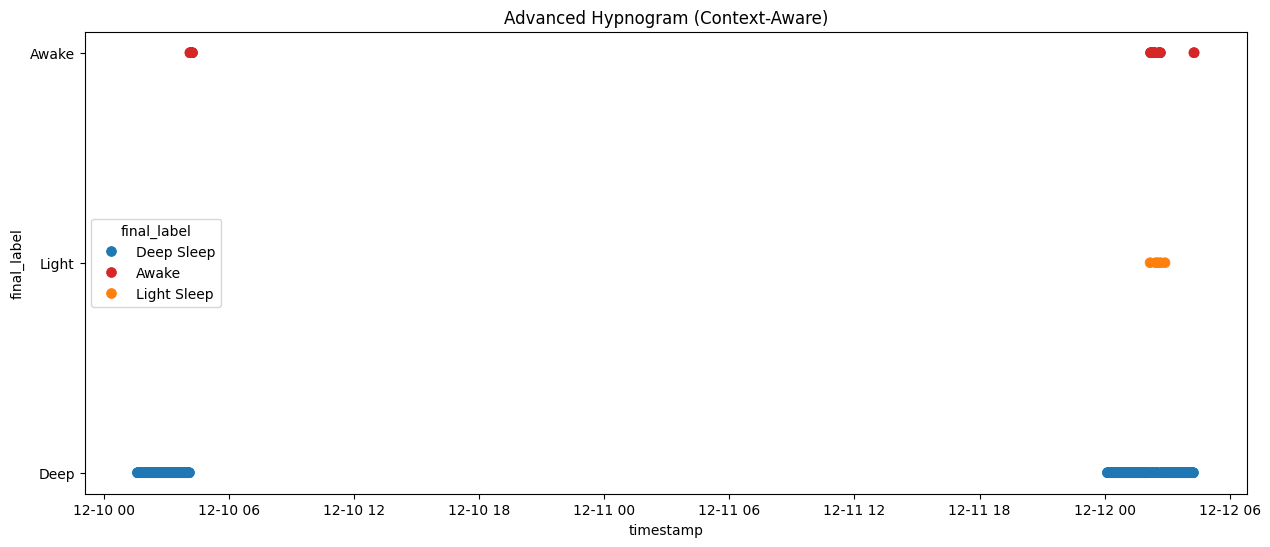


--- Sleep Statistics ---
                         mean       std  active_count  roll_active  roll_std  \
timestamp                                                                      
2025-12-10 01:36:00  0.014285  0.006031      0.423189     0.538939  0.147253   
2025-12-10 01:37:00  0.014170  0.006117      0.416504     0.434881  0.014872   
2025-12-10 01:38:00  0.014145  0.006080      0.407925     0.411589  0.006077   
2025-12-10 01:39:00  0.014063  0.006061      0.401754     0.409316  0.006084   
2025-12-10 01:40:00  0.014240  0.006098      0.408574     0.411432  0.006102   
...                       ...       ...           ...          ...       ...   
2025-12-12 04:14:00  0.014354  0.006218      0.424164     0.421945  0.006064   
2025-12-12 04:15:00  0.014143  0.006112      0.417993     0.418642  0.006026   
2025-12-12 04:16:00  0.014155  0.005849      0.424488     0.448847  0.033690   
2025-12-12 04:17:00  0.014137  0.005944      0.403378     0.547320  0.405483   
2025-12-12 04:

In [30]:
# --- MAIN EXECUTION ---
if __name__ == "__main__":
    # 1. Load your specific files
    files = ['data/sleep_data1.csv', 'data/sleep_data2.csv']
    
    # Run Pipeline
    raw_df = load_and_process_data(files)
    adv_features = create_advanced_features(raw_df, threshold=0.015) # Tuning threshold is key
    final_df = train_hierarchical_model(adv_features)
    interpret_and_plot(final_df)
    
    # Stats
    print("\n--- Sleep Statistics ---")
    print(final_df)